# Shared clip data: from video to model-ready numbers

This notebook shows how one tactical clip becomes the data **every** strategy model reads:
the TCN, the GRU, the tactic baseline and any new model. **It does not train any model.**

It combines two pieces of the team's work:

| Source | Who | What it gives |
|---|---|---|
| **Player and bomb detector** | zhengyongheng1, on Gin's colour baseline | Where each T and CT icon is, and the C4 badge, on every frame |
| **Frozen ResNet-18 features** | jx (tactic baseline) | 512 general "what the map looks like" numbers per frame |

New in this step:
- **named map regions** (ramp, connector, short...), so positions can be described in the
  same terms as the tactic rules
- a **bomb state and plant estimate**
- **one shared timeline** for both sources

Full reference: [`docs/clip-data.md`](../docs/clip-data.md). The data was built with:

```powershell
.\.venv\Scripts\python.exe -m stratscout build-clip-data --dataset data/processed/datasets/2026-11-16 --output runs/clip-data-2026-11-16
```

This notebook only reads that folder and the detection cache, so it runs in about a minute.
Open it in VS Code with the `.venv` kernel and choose **Run All**.

## The flow

```
                       ┌────────────────────────── one clip (10 fps radar video) ──────────────────────────┐
                       │                                                                                    │
          every frame  ▼                                                          every 2nd frame (5/s)     ▼
   ┌───────────────────────────────┐                                       ┌──────────────────────────────────┐
   │ DETECTOR  (zhengyongheng1)     │                                       │ RESNET-18  (jx's baseline)        │
   │ colour + shape rules:          │                                       │ resize whole frame to 224×224     │
   │ T/CT icons, death markers out, │                                       │ frozen ImageNet network           │
   │ overlapping icons split, C4    │                                       │ → 512 numbers per frame           │
   └───────────────┬───────────────┘                                       └──────────────────┬───────────────┘
                   │ dots: (frame, x, y, team, inferred) + bomb                                  │ 512 per row
                   ▼                                                                             │
   ┌───────────────────────────────┐                                                            │
   │ REGIONS + BOMB STATE (new)     │                                                            │
   │ which named area each dot is in│                                                            │
   │ replay the BombStateTracker    │                                                            │
   └───────────────┬───────────────┘                                                            │
                   ▼                                                                             ▼
   ┌────────────────────────────────────────────────────────────────────────────────────────────────────────┐
   │ ONE PACKAGE PER CLIP  (runs/clip-data-2026-11-16/clips/<clip>.npz)                                       │
   │   detector : rows × 72   (one row every 0.2 s)        resnet : rows × 512   (same rows)                  │
   │   summary  : 30          (the whole clip in one row)                                                    │
   └────────────────────────────────────────────────────────────────────────────────────────────────────────┘
                   │  per cross-validation fold: compress ResNet 512 → 32, fitted on training clips only
                   ▼
           X : rows × 104  +  mask        →  TCN / GRU          S : 62 numbers  →  simple models
```

In [1]:
import json
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

from stratscout.clip_data import NEVER_S, Regions, ResnetCompressor, assemble, load_clip_data, pad
from stratscout.config import TACTIC_CLASSES
from stratscout.tactic_features import cached_detections, load_dataset, match_background

DATA = Path("runs/clip-data-2026-11-16")
DATASET = Path("data/processed/datasets/2026-11-16")
channels = json.loads((DATA / "channels.json").read_text())
clips = load_clip_data(DATA)
by_id = {c["clip_id"]: c for c in clips}
regions = Regions.load()

T_COL, CT_COL, INK, MUTED = "#eb6834", "#2a78d6", "#0b0b0b", "#898781"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
REGION_COL = dict(zip(regions.names, SERIES + ["#52514e", "#b9b8b1"]))
BLUES = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#86b6ef", "#2a78d6", "#0d366b"])
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)
print(f"{len(clips)} clips; data {channels['data_version']}, regions {channels['regions_version']}")
print(
    f"{len(channels['detector'])} detector channels per row, {len(channels['summary'])} summary values per clip, "
    f"{channels['rows_per_second']:.0f} rows per second"
)
pd.read_csv(DATA / "index.csv").groupby(["split", "label"]).size().unstack(fill_value=0)[
    list(TACTIC_CLASSES)
]

128 clips; data clip-data-1, regions mirage-spectator-v1
72 detector channels per row, 30 summary values per clip, 5 rows per second


label,A_DIRECT,B_DIRECT,A_SPLIT,B_SPLIT,RETAKE
split,,,,,
test,15,6,6,5,13
train,15,24,15,9,20


## Step 1: the detector finds the dots

The detector looks at every frame and keeps vivid T-coloured and CT-coloured blobs that
differ from the empty map. It drops death markers (✕, which have no white arrow), splits
blobs that hold several overlapping icons, caps each team at 5, and finds the C4 badge.
If the bomb carrier is hidden under the badge, it adds an **inferred** T there.

Its output for one frame is just a list of dots. Here is an A_SPLIT clip from
Vitality–Falcons: one frame, then every dot in the clip.

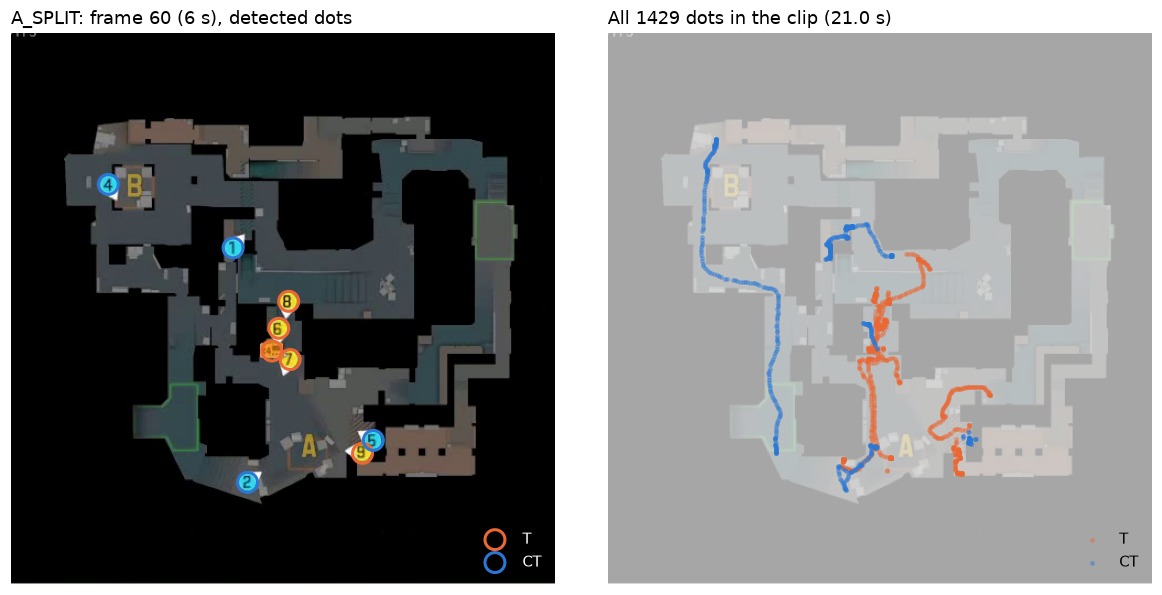

In [2]:
rows = load_dataset(DATASET)
row_of = {r["clip_id"]: r for r in rows}
dets = cached_detections(rows, "runs/tactic-cache", log=lambda m: None)

CLIP = "vitality-falcons-mirage-esl-pro-league-season-24.jx.s011"
clip, det, row = by_id[CLIP], dets[CLIP], row_of[CLIP]
players = det["players"]
match_rows = [r for r in rows if r["match"] == row["match"]]
background = match_background([r["path"] for r in match_rows])  # the empty map for this match
h, w = background.shape[:2]

frame_no = 60
cap = cv2.VideoCapture(str(row["path"]))
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no)
ok, bgr = cap.read()
cap.release()
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 5.4))
a.imshow(rgb)
here = players[players[:, 0] == frame_no]
for team, col, name in ((0, T_COL, "T"), (1, CT_COL, "CT")):
    p = here[here[:, 3] == team]
    a.scatter(
        p[:, 1] * w, p[:, 2] * h, s=170, facecolors="none", edgecolors=col, linewidths=2, label=name
    )
a.set_title(f"{clip['label']}: frame {frame_no} ({frame_no / 10:.0f} s), detected dots", loc="left")
a.legend(loc="lower right", labelcolor="white")
a.axis("off")
b.imshow(background, alpha=0.35)
for team, col, name in ((0, T_COL, "T"), (1, CT_COL, "CT")):
    p = players[players[:, 3] == team]
    b.scatter(p[:, 1] * w, p[:, 2] * h, s=5, color=col, alpha=0.35, label=name)
b.set_title(f"All {len(players)} dots in the clip ({len(det['bomb']) / 10:.1f} s)", loc="left")
b.legend(loc="lower right")
b.axis("off")
plt.tight_layout()
plt.show()

## Step 2: dots become named map regions

A dot at `(0.48, 0.58)` means nothing to a person, but "a T in **connector**" does. The
tactic rules are written in those terms, so each dot is placed in a region from
[`stratscout/mirage_regions.json`](../stratscout/mirage_regions.json). Each region is a few
rectangles on the radar, and a dot belongs to the first region that contains it.

**The regions are a draft** (`mirage-spectator-v1`; v1 moved `short` onto the real mid → B route, see the doc). Please check the boundaries: it's a
JSON file, easy to adjust and rebuild.

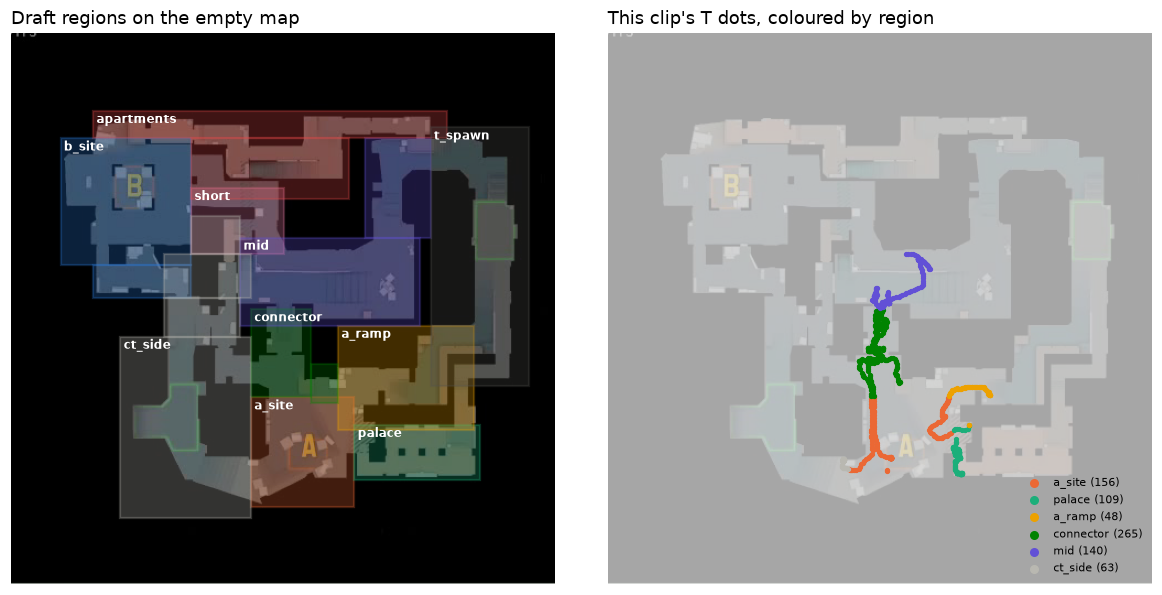

Dots in a named region, whole dataset: 100.0%


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 5.4))
a.imshow(background)
for name, rects in zip(regions.names, regions.rects):
    for x0, y0, x1, y1 in rects:
        a.add_patch(
            Rectangle(
                (x0 * w, y0 * h),
                (x1 - x0) * w,
                (y1 - y0) * h,
                fill=True,
                alpha=0.28,
                facecolor=REGION_COL[name],
                edgecolor=REGION_COL[name],
                lw=1.5,
            )
        )
    x0, y0 = rects[0][:2]
    a.text(x0 * w + 3, y0 * h + 11, name, color="white", fontsize=8, weight="bold")
a.set_title("Draft regions on the empty map", loc="left")
a.axis("off")

t = players[players[:, 3] == 0]
idx = regions.index(t[:, 1:3])
b.imshow(background, alpha=0.35)
for i, name in enumerate(regions.names):
    p = t[idx == i]
    if len(p):
        b.scatter(p[:, 1] * w, p[:, 2] * h, s=6, color=REGION_COL[name], label=f"{name} ({len(p)})")
b.set_title("This clip's T dots, coloured by region", loc="left")
b.axis("off")
b.legend(loc="lower right", fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

all_p = np.concatenate([d["players"] for d in dets.values()])
print(f"Dots in a named region, whole dataset: {np.mean(regions.index(all_p[:, 1:3]) >= 0):.1%}")

## Step 3: one row every 0.2 s, the detector channels

For every row (every second frame, so 5 per second), the dots become **72 named numbers**.
The most important groups:

- `t_in_<region>`: how many Ts are in each region (÷ 5)
- `t_reached_<region>`: has any T reached this region yet? It switches on once and stays on,
  so the model sees the **route history**, not just where players end up.
- `t_flow_<region>`: change since the last row, i.e. which way the team is moving
- counts, centroids, spread, distances to the sites, bomb state, time, and quality flags

Counts are smoothed over 3 rows (0.6 s) first, so a single bad frame can't mark a region as
reached. Below: where the Ts are over time in the A_SPLIT clip. Darker means more Ts.

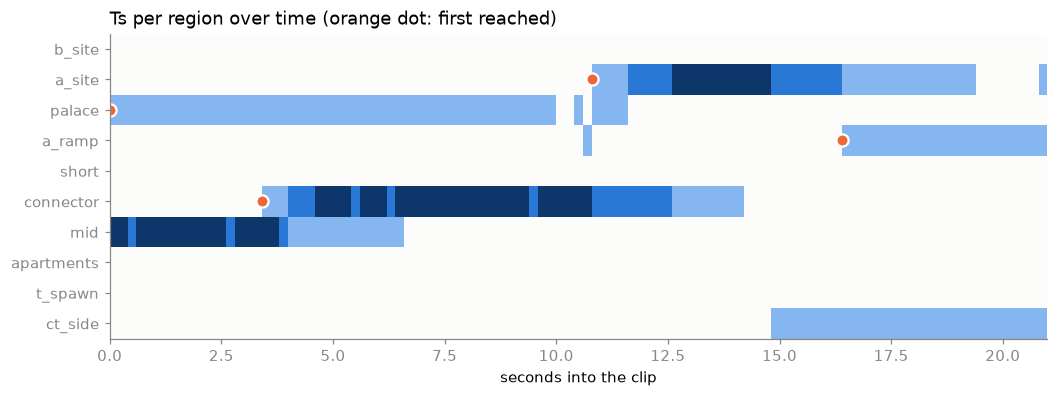

First T on ramp/palace: 0.0 s; first T in connector: 3.4 s; A split gap: 3.4 s


In [4]:
names = clip["detector_names"]
x = clip["detector"]
t_s = clip["t_s"]
t_cols = [names.index(f"t_in_{n}") for n in regions.names]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(
    x[:, t_cols].T * 5,
    aspect="auto",
    cmap=BLUES,
    vmin=0,
    vmax=3,
    extent=[t_s[0], t_s[-1] + 0.2, len(regions.names) - 0.5, -0.5],
    interpolation="nearest",
)
ax.set_yticks(range(len(regions.names)), regions.names)
ax.grid(False)
for n in ("a_ramp", "palace", "connector", "a_site"):
    r = np.nonzero(x[:, names.index(f"t_reached_{n}")] > 0)[0]
    if len(r):
        ax.plot(
            t_s[r[0]], regions.names.index(n), marker="o", ms=8, color=T_COL, mec="white", mew=1.5
        )
ax.set_xlabel("seconds into the clip")
ax.set_title("Ts per region over time (orange dot: first reached)", loc="left")
plt.show()

s, s_names = clip["summary"], clip["summary_names"]
print(
    f"First T on ramp/palace: {min(s[s_names.index('first_t_a_ramp_s')], s[s_names.index('first_t_palace_s')]):.1f} s; "
    f"first T in connector: {s[s_names.index('first_t_connector_s')]:.1f} s; "
    f"A split gap: {s[s_names.index('a_split_gap_s')]:.1f} s"
)

Two approaches used within a few seconds of each other is exactly the tactic guide's split
rule (final approaches within about 10 s). The data now carries that as numbers, but **it's
a feature, not a label**: the models still learn what matters.

## Step 4: the bomb's state and an estimated plant

The detector's `BombStateTracker` (zhengyongheng1) labels the C4 badge on every frame:

- **carried:** the carrier's ring shows at the badge edge
- **alone:** no carrier, but not still for long enough yet
- **dropped:** still and alone for 2 s
- **missing:** no badge found

The data replays it on the cached badge positions. If the badge is **dropped on a site**,
it's taken as an **estimated plant** from then on. That matters for RETAKE. A dropped bomb
lying on a site can't be told apart from a planted one, so it's an estimate.

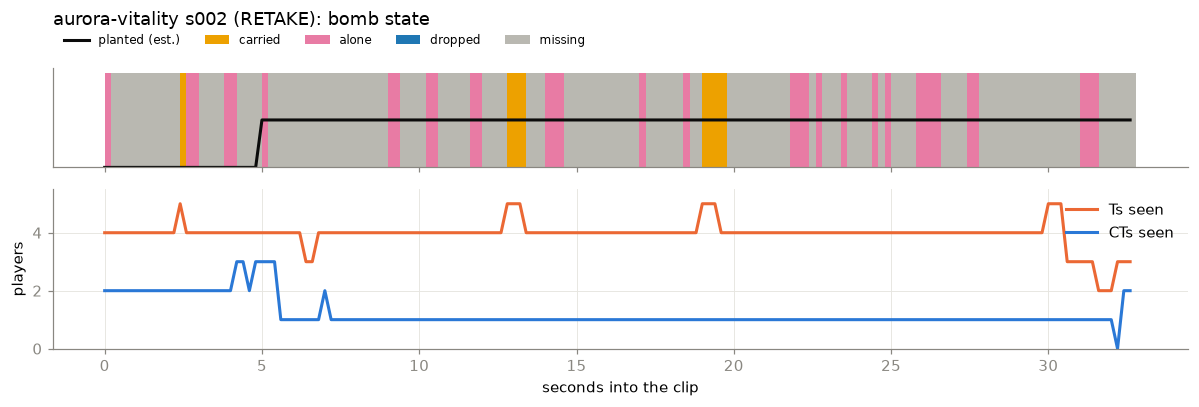

RETAKE clips with an estimated plant: 73%


In [5]:
retakes = [
    c
    for c in clips
    if c["label"] == "RETAKE" and c["summary"][c["summary_names"].index("planted_est")] > 0
]
rc = retakes[0]
rn, rx, rt = rc["detector_names"], rc["detector"], rc["t_s"]
state_cols = ["bomb_carried", "bomb_alone", "bomb_dropped", "bomb_missing"]
state = np.argmax(rx[:, [rn.index(c) for c in state_cols]], 1)

fig, (a, b) = plt.subplots(
    2, 1, figsize=(11, 3.8), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]}
)
state_colours = ["#eda100", "#e87ba4", "#e34948", "#b9b8b1"]
for k, (label, col) in enumerate(zip(["carried", "alone", "dropped", "missing"], state_colours)):
    on = state == k
    a.bar(rt[on], 1, width=0.2, color=col, label=label, align="edge")
a.plot(rt, rx[:, rn.index("bomb_planted_est")] * 0.5, color=INK, lw=2, label="planted (est.)")
a.set_yticks([])
a.legend(loc="upper left", ncol=5, fontsize=8, bbox_to_anchor=(0, 1.45))
a.grid(False)
a.set_title(
    f"{rc['clip_id'].split('.jx.')[0].split('-mirage')[0]} {rc['clip_id'].split('.jx.')[1]} (RETAKE): bomb state",
    loc="left",
    pad=28,
)
for team, col, lab in (("t", T_COL, "Ts seen"), ("ct", CT_COL, "CTs seen")):
    b.plot(rt, rx[:, rn.index(f"{team}_seen")] * 5, color=col, lw=2, label=lab)
b.set_ylabel("players")
b.set_xlabel("seconds into the clip")
b.legend(loc="upper right")
b.set_ylim(0, 5.5)
plt.tight_layout()
plt.show()
share = np.mean(
    [
        c["summary"][c["summary_names"].index("planted_est")] > 0
        for c in clips
        if c["label"] == "RETAKE"
    ]
)
print(f"RETAKE clips with an estimated plant: {share:.0%}")

## Step 5: the ResNet features on the same rows

jx's tactic baseline uses a **frozen ResNet-18** pretrained on everyday photos (ImageNet).
For each row, the **whole** radar frame is shrunk to 224×224 and passed through it, giving
512 numbers. They describe the image's general appearance (edges, textures, colours by
area). Nothing in them says "a player is here".

Two things to notice:

1. **Shrinking costs detail.** The icons are about 18 px across on the 494×500 crop, and
   about 8 px after shrinking.
2. **512 numbers is a lot** for 82 training clips. So the data stores them raw, and each
   model **compresses them to 32 per fold** with PCA (`ResnetCompressor`), fitted on that
   fold's **training clips only**. Here the example fold holds out Aurora–Vitality.

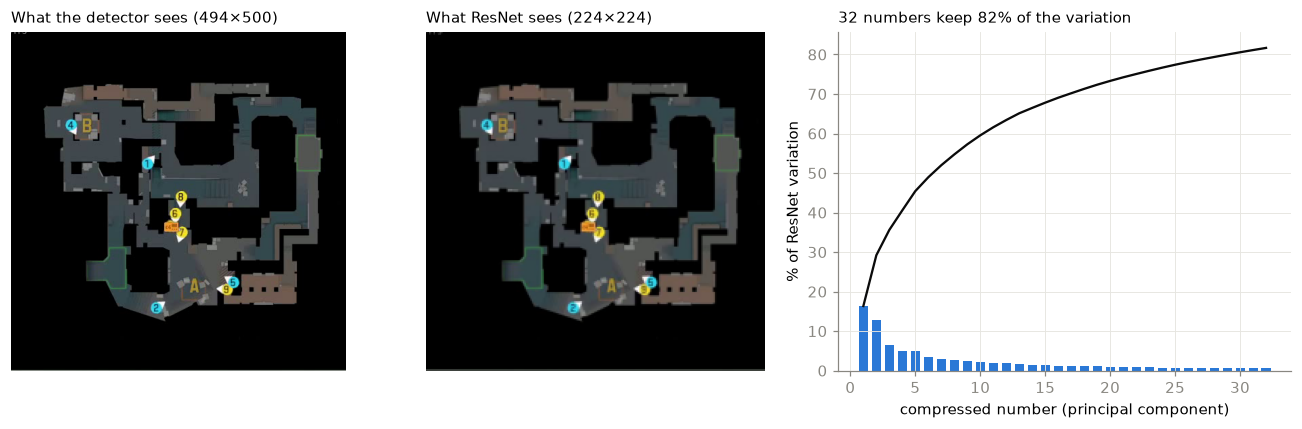

ResNet rows for this clip: (105, 512) (rows × 512), stored as float16


In [6]:
small = cv2.resize(rgb, (224, 224), interpolation=cv2.INTER_AREA)
fig, (a, b, c) = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1, 1.3]})
a.imshow(rgb)
a.set_title(f"What the detector sees ({w}×{h})", loc="left", fontsize=10)
a.axis("off")
b.imshow(small)
b.set_title("What ResNet sees (224×224)", loc="left", fontsize=10)
b.axis("off")

held = "aurora-vitality-mirage-esl-pro-league-season-24"
fold_train = [
    k for k in clips if k["split"] == "train" and k["match"] != held and not k["uncertain"]
]
comp = ResnetCompressor(32).fit([k["resnet"] for k in fold_train])
stacked = np.concatenate([k["resnet"].astype(np.float32) for k in fold_train])
var = np.var((stacked - comp.mean) @ comp.components.T, 0) / np.var(stacked - comp.mean, 0).sum()
c.bar(np.arange(1, 33), var * 100, color=CT_COL, width=0.7)
c.plot(np.arange(1, 33), np.cumsum(var) * 100, color=INK, lw=1.5)
c.set_xlabel("compressed number (principal component)")
c.set_ylabel("% of ResNet variation")
c.set_title(f"32 numbers keep {np.sum(var):.0%} of the variation", loc="left", fontsize=10)
plt.tight_layout()
plt.show()
print(f"ResNet rows for this clip: {clip['resnet'].shape} (rows × 512), stored as float16")

**A check worth doing: what does ResNet actually pick up?** Below, each training clip is one
dot: its average first two compressed ResNet numbers. On the left the dots are coloured by
**tactic**, on the right by **match**. If they cluster by match more than by tactic, the
image features mostly describe *which recording* a clip is from (lighting, HUD, observer),
not the tactic. That's a risk for generalising to new matches, and it's why they're kept
small next to the detector channels.

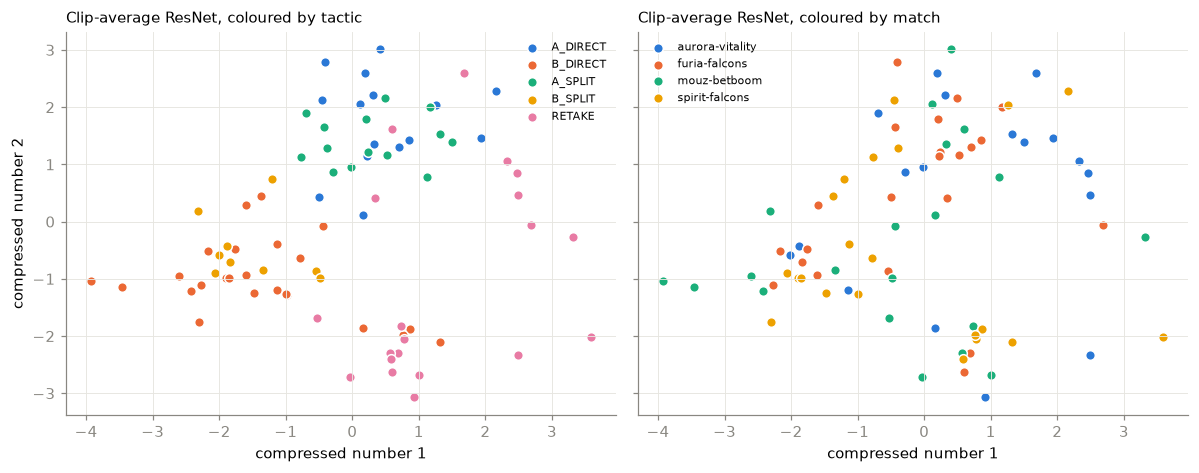

In [7]:
train_all = [k for k in clips if k["split"] == "train" and not k["uncertain"]]
comp_all = ResnetCompressor(2).fit([k["resnet"] for k in train_all])
pts = np.array([comp_all(k["resnet"]).mean(0) for k in train_all])
matches = sorted({k["match"] for k in train_all})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, key, values, title in (
    (axes[0], "label", list(TACTIC_CLASSES), "coloured by tactic"),
    (axes[1], "match", matches, "coloured by match"),
):
    for v, col in zip(values, SERIES):
        sel = [i for i, k in enumerate(train_all) if k[key] == v]
        ax.scatter(
            pts[sel, 0],
            pts[sel, 1],
            s=40,
            color=col,
            edgecolors="white",
            lw=1,
            label=v.split("-mirage")[0] if key == "match" else v,
        )
    ax.set_title(f"Clip-average ResNet, {title}", loc="left", fontsize=10)
    ax.set_xlabel("compressed number 1")
    ax.legend(fontsize=7, loc="best")
axes[0].set_ylabel("compressed number 2")
plt.tight_layout()
plt.show()

**What it shows on this data.** The dots group by **tactic** more than by **match**: B
tactics on the left, A tactics at the top, retakes at the bottom, while the matches are
mixed together. So the whole-map image features do carry tactic information, probably
because the picture changes with where the icons are. They're still kept compressed next
to the detector channels, because with only four training matches a recording effect
can't be ruled out. (The compressor here is fitted on all training clips for display
only; models fit it per fold.)

## Step 6: the package a model receives

For each fold, a model:

1. fits `ResnetCompressor` on that fold's training clips
2. calls `assemble(clip, compressor)` to get **X**, rows × (72 detector + 32 ResNet) = 104
   columns, and **S**, 30 summary + 32 ResNet averages = 62 values
3. calls `pad` to batch clips of different lengths, with a **mask** marking real rows

Sequence models (TCN, GRU) take `X` + `mask`; simple models take `S`.

In [8]:
x_full, x_names, s_full, s_names = assemble(clip, comp)
X, mask = pad([assemble(k, comp)[0] for k in fold_train[:8]])
print(
    f"one clip: X {x_full.shape} = rows × ({len(clip['detector_names'])} detector + 32 ResNet); S {s_full.shape}"
)
print(
    f"a batch of 8: X {X.shape} = clips × longest rows × columns; mask {mask.shape}, "
    f"real rows per clip {mask.sum(1).astype(int).tolist()}"
)
groups = pd.Series(
    [
        n.split("_")[0] + "_" + n.split("_")[1]
        if n.startswith(("t_in", "ct_in", "t_reached", "t_flow", "ct_flow"))
        else (
            "resnet" if n.startswith("resnet") else "other (counts, centroids, bomb, time, quality)"
        )
        for n in x_names
    ]
)
groups.value_counts().rename("columns").to_frame()

one clip: X (105, 104) = rows × (72 detector + 32 ResNet); S (62,)
a batch of 8: X (8, 178, 104) = clips × longest rows × columns; mask (8, 178), real rows per clip [139, 54, 157, 48, 178, 95, 47, 177]


,columns
resnet,32
"other (counts, centroids, bomb, time, quality)",22
t_in,10
ct_in,10
t_reached,10
t_flow,10
ct_flow,10


In [9]:
# The summary rows of a few clips side by side (times in seconds; 60 = never)
show = [
    "first_t_a_ramp_s",
    "first_t_palace_s",
    "first_t_connector_s",
    "first_t_apartments_s",
    "first_t_short_s",
    "a_split_gap_s",
    "b_split_gap_s",
    "planted_est",
    "plant_time_s",
    "t_spread_mean",
    "duration_s",
]
sample = [
    next(k for k in clips if k["split"] == "train" and k["label"] == c) for c in TACTIC_CLASSES
]
pd.DataFrame(
    [[k["summary"][k["summary_names"].index(n)] for n in show] for k in sample],
    index=[f"{k['label']} ({k['clip_id'].split('-mirage')[0]})" for k in sample],
    columns=show,
).round(1)

,first_t_a_ramp_s,first_t_palace_s,first_t_connector_s,first_t_apartments_s,first_t_short_s,a_split_gap_s,b_split_gap_s,planted_est,plant_time_s,t_spread_mean,duration_s
A_DIRECT (aurora-vitality),2.6,0.0,60.0,60.0,60.0,60.0,60.0,0.0,60.0,0.2,23.600000
B_DIRECT (aurora-vitality),60.0,60.0,60.0,0.0,60.0,60.0,60.0,0.0,60.0,0.1,20.000000
A_SPLIT (aurora-vitality),0.0,0.0,0.0,60.0,60.0,0.0,60.0,0.0,60.0,0.1,28.200001
B_SPLIT (aurora-vitality),60.0,60.0,60.0,0.0,0.4,60.0,0.4,0.0,60.0,0.1,19.600000
RETAKE (aurora-vitality),60.0,60.0,60.0,0.0,60.0,60.0,60.0,1.0,5.0,0.1,32.799999


## Step 7: does the data separate the tactics?

Before any model, check that the numbers say something sensible on the **training clips**.
Labels are used here only to describe the data, never to build it.

- **Reach:** do A_SPLIT clips reach connector more often than A_DIRECT? Do B_SPLIT clips
  reach short more than B_DIRECT?
- **Split gap:** how many seconds apart the two approaches start (when both are used)
- **Plant:** do RETAKE clips have an estimated plant?

,clips,reach connector,reach ramp/palace,reach short,reach apartments,plant (est.)
class,,,,,,
A_DIRECT,15,60%,100%,7%,13%,20%
B_DIRECT,24,0%,8%,8%,100%,0%
A_SPLIT,14,100%,100%,7%,14%,7%
B_SPLIT,9,11%,11%,89%,100%,11%
RETAKE,20,25%,25%,5%,50%,75%


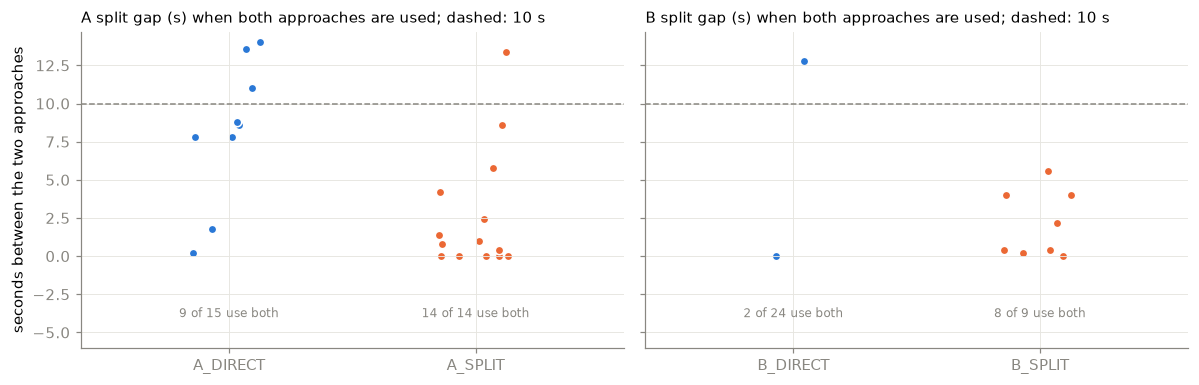

In [10]:
train = [k for k in clips if k["split"] == "train" and not k["uncertain"]]


def value(k, n):
    return k["summary"][k["summary_names"].index(n)]


table = []
for c in TACTIC_CLASSES:
    g = [k for k in train if k["label"] == c]
    table.append(
        {
            "class": c,
            "clips": len(g),
            "reach connector": np.mean([value(k, "first_t_connector_s") < NEVER_S for k in g]),
            "reach ramp/palace": np.mean(
                [
                    min(value(k, "first_t_a_ramp_s"), value(k, "first_t_palace_s")) < NEVER_S
                    for k in g
                ]
            ),
            "reach short": np.mean([value(k, "first_t_short_s") < NEVER_S for k in g]),
            "reach apartments": np.mean([value(k, "first_t_apartments_s") < NEVER_S for k in g]),
            "plant (est.)": np.mean([value(k, "planted_est") > 0 for k in g]),
        }
    )
display(
    pd.DataFrame(table)
    .set_index("class")
    .style.format(
        "{:.0%}",
        subset=pd.IndexSlice[
            :,
            [
                "reach connector",
                "reach ramp/palace",
                "reach short",
                "reach apartments",
                "plant (est.)",
            ],
        ],
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, gap, pair in (
    (axes[0], "a_split_gap_s", ("A_DIRECT", "A_SPLIT")),
    (axes[1], "b_split_gap_s", ("B_DIRECT", "B_SPLIT")),
):
    for i, (c, col) in enumerate(zip(pair, (CT_COL, T_COL))):
        g = np.array([value(k, gap) for k in train if k["label"] == c])
        both = g[g < NEVER_S]
        jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(both))
        ax.scatter(np.full(len(both), i) + jitter, both, s=30, color=col, edgecolors="white", lw=1)
        ax.text(i, -4, f"{len(both)} of {len(g)} use both", ha="center", fontsize=8, color=MUTED)
    ax.axhline(10, color=MUTED, ls="--", lw=1)
    ax.set_xticks([0, 1], pair)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(-6, None)
    ax.set_title(
        f"{'A' if gap[0] == 'a' else 'B'} split gap (s) when both approaches are used; dashed: 10 s",
        loc="left",
        fontsize=10,
    )
axes[0].set_ylabel("seconds between the two approaches")
plt.tight_layout()
plt.show()

**What it shows on this data (training clips):**

- **A:** all 14 A_SPLIT clips use both approaches, mostly within 2.5 s. 9 of 15 A_DIRECT
  clips also show a T in connector, but usually 7–14 s after the main push. That's a late
  lurker or flank, or the connector box catching Ts at the edge of A site. The gap
  separates them better than "reached connector" alone.
- **B:** 8 of 9 B_SPLIT clips use apartments and short, against 2 of 24 B_DIRECT.
- **RETAKE:** 75% have an estimated plant, against 0–20% for the attack classes.

How to read this:

- A clean result would be: **A_SPLIT reaches connector far more often than A_DIRECT**,
  **B_SPLIT reaches short more than B_DIRECT**, and splits have **short gaps** (under about
  10 s). The more the classes differ here, the less the models have to work out themselves.
- Where the classes **overlap** (e.g. direct attacks that also show a T in connector),
  there are three possible causes: a lurker or a flank that isn't a coordinated split,
  detector noise, or a region boundary that needs adjusting. Those cases are worth a look
  with the team.
- **RETAKE with no estimated plant** usually means the badge was hidden or never still
  long enough in the clip.

## How each model will use this

| Model | Reads | Replaces |
|---|---|---|
| TCN | `X` + `mask` (104 per row) | its own 141 grid features |
| GRU (jx) | `X` + `mask` (104 per row) | 512 ResNet or 260 position numbers on 16 frames |
| Tactic baseline / simple models | `S` (62 per clip) | the mean of 512 ResNet numbers |
| New model (teammate) | either | – |

**Shared rules:**
- same dataset, exclusions, test matches and folds for everyone
- fit scaling and the ResNet compressor per fold on training clips only
- record `data_version` and `regions_version` with every result

**Limits:**
- the detector is an unvalidated colour detector (jx's detector check measures it)
- the regions are a draft
- there's no time since round start yet (needs the recordings)
- ResNet sees an 8 px icon world
- Mirage and the spectator radar only

**Next step (not done here):** retrain the models on this data and compare them on the same
protocol: with and without the ResNet part, and with and without regions.